ЛР 1

Лабораторная работа № 1. Вариант 4
a=1.0, L=pi, T=1.0, Nx=40, Nt=400
h=0.078540, tau=0.002500, sigma_explicit=0.405285
Важно: для явной схемы sigma должно быть не больше 0.5.

Явная                  | двухточечная, 1-й порядок        | max error = 9.327828e-04
    Погрешность в выбранные моменты времени:
      t=0.0000: max_x |u-U| = 0.000000e+00
      t=0.2500: max_x |u-U| = 5.847255e-04
      t=0.5000: max_x |u-U| = 7.598053e-04
      t=0.7500: max_x |u-U| = 8.633113e-04
      t=1.0000: max_x |u-U| = 9.327828e-04
Явная                  | трёхточечная, 2-й порядок        | max error = 1.064620e-03
    Погрешность в выбранные моменты времени:
      t=0.0000: max_x |u-U| = 0.000000e+00
      t=0.2500: max_x |u-U| = 9.247560e-04
      t=0.5000: max_x |u-U| = 1.054117e-03
      t=0.7500: max_x |u-U| = 1.059500e-03
      t=1.0000: max_x |u-U| = 1.029542e-03
Явная                  | двухточечная, 2-й порядок        | max error = 9.027329e-04
    Погрешность в выбранные моменты времени:
    

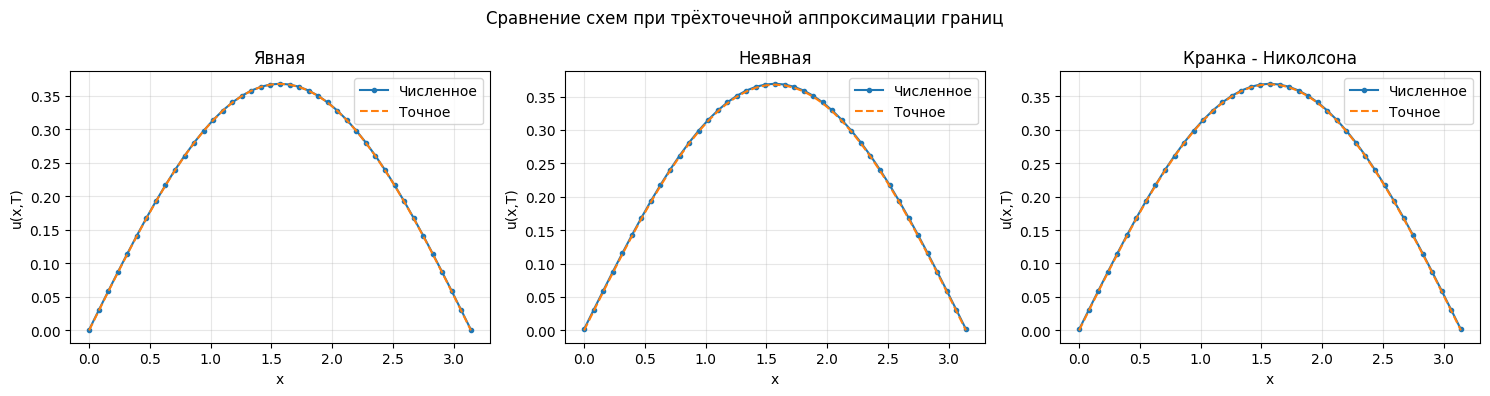

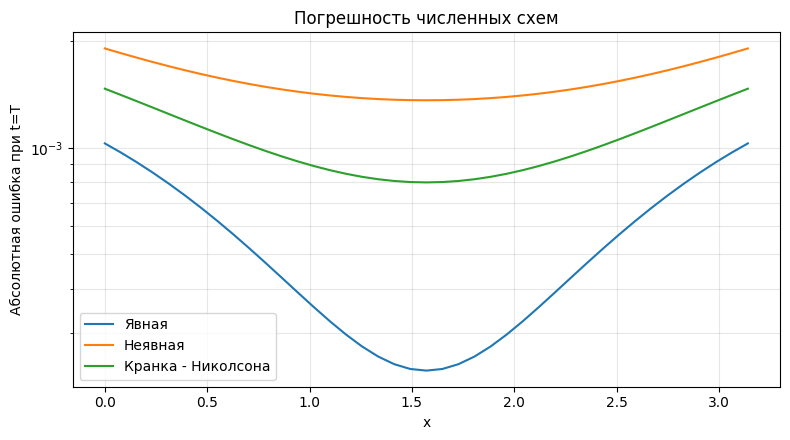


Графики сохранены: lab1_comparison.png, lab1_error.png

Зависимость ошибки от пространственного шага (tau примерно фиксирован):
Nx= 10, h=0.314159, max error=2.313158e-02
Nx= 20, h=0.157080, max error=5.862445e-03
Nx= 40, h=0.078540, max error=1.470645e-03
Nx= 80, h=0.039270, max error=3.679608e-04

Зависимость ошибки от временного шага (Nx=100):
Nt=  50, tau=0.020000, max error=2.218007e-04
Nt= 100, tau=0.010000, max error=2.316426e-04
Nt= 200, tau=0.005000, max error=2.343746e-04
Nt= 400, tau=0.002500, max error=2.351932e-04
Nt= 800, tau=0.001250, max error=2.354657e-04


In [1]:
# -*- coding: utf-8 -*-
"""
ЛАБОРАТОРНАЯ РАБОТА № 1
Одномерное уравнение теплопроводности.
Вариант 4 из задания:

    u_t = a * u_xx,       0 < x < pi, 0 < t <= T
    u_x(0,t) = exp(-a*t)
    u_x(pi,t) = -exp(-a*t)
    u(x,0) = sin(x)

Точное решение: U(x,t) = exp(-a*t) * sin(x).

В программе сравниваются:
  1) явная конечно-разностная схема;
  2) неявная конечно-разностная схема;
  3) схема Кранка - Николсона.

Для каждой схемы проверяются три варианта аппроксимации производных
на границах. Комментарии поясняют как назначение блоков, так и смысл формул.
"""

# ============================================================================
# БЛОК 1. БИБЛИОТЕКИ И ПАРАМЕТРЫ ИСХОДНОЙ ЗАДАЧИ
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

A_DIFFUSION = 1.0       # коэффициент a в уравнении теплопроводности
L = np.pi               # длина отрезка по x
T_FINAL = 1.0           # конечный момент времени


# ============================================================================
# БЛОК 2. ТОЧНОЕ РЕШЕНИЕ И ГРАНИЧНЫЕ УСЛОВИЯ
# ============================================================================
def exact_solution(x, t):
    """Вернуть точное значение U(x,t) = exp(-a*t)*sin(x)."""
    return np.exp(-A_DIFFUSION * t) * np.sin(x)


def left_derivative(t):
    """Значение производной u_x(0,t), заданное в условии задачи."""
    return np.exp(-A_DIFFUSION * t)


def right_derivative(t):
    """Значение производной u_x(L,t), заданное в условии задачи."""
    return -np.exp(-A_DIFFUSION * t)


def validate_boundary_type(bc_type):
    """Проверить название способа аппроксимации граничных условий."""
    allowed = {"two_point_first", "three_point_second", "two_point_second"}
    if bc_type not in allowed:
        raise ValueError(f"Неизвестный тип граничного условия: {bc_type}. Допустимо: {sorted(allowed)}")


# ============================================================================
# БЛОК 3. РЕШЕНИЕ ТРЁХДИАГОНАЛЬНОЙ СИСТЕМЫ
# ============================================================================
def solve_tridiagonal(lower, diagonal, upper, rhs):
    """
    Решить систему с трёхдиагональной матрицей.

    lower   - нижняя диагональ;
    diagonal- главная диагональ;
    upper   - верхняя диагональ;
    rhs     - правая часть.

    Используется solve_banded из SciPy. Это готовая реализация решения
    ленточной системы; в этой лабораторной она заменяет ручную прогонку.
    Первый элемент lower и последний элемент upper не используются.
    """
    n = len(diagonal)
    if not (len(lower) == len(upper) == len(rhs) == n):
        raise ValueError("Все диагонали и правая часть должны иметь одинаковую длину.")

    # Формат SciPy: строка 0 - верхняя диагональ,
    # строка 1 - главная, строка 2 - нижняя.
    banded = np.zeros((3, n), dtype=float)
    if n > 1:
        banded[0, 1:] = upper[:-1]
        banded[2, :-1] = lower[1:]
    banded[1, :] = diagonal

    return solve_banded((1, 1), banded, rhs)


# ============================================================================
# БЛОК 4. ОБЩАЯ ФУНКЦИЯ ДЛЯ ВЫЧИСЛЕНИЯ ГРАНИЧНЫХ ЗНАЧЕНИЙ
# ============================================================================
def set_boundary_values(u_new, u_old, h, tau, t_new, bc_type):
    """
    Заполнить два граничных узла нового временного слоя.

    u_new - слой, на котором уже рассчитаны внутренние узлы;
    u_old - предыдущий временной слой;
    h     - шаг по пространству;
    tau   - шаг по времени;
    t_new - момент времени нового слоя.

    Важно: справа используется u_N = u_(N-1) + h*g_right.
    Знак именно ПЛЮС, потому что производная задана как
    (u_N - u_(N-1))/h = g_right.
    """
    validate_boundary_type(bc_type)
    g_l = left_derivative(t_new)
    g_r = right_derivative(t_new)
    n = len(u_new) - 1

    if bc_type == "two_point_first":
        # Односторонняя разность первого порядка.
        u_new[0] = u_new[1] - h * g_l
        u_new[n] = u_new[n - 1] + h * g_r

    elif bc_type == "three_point_second":
        # Односторонняя трёхточечная формула второго порядка.
        if n < 3:
            raise ValueError("Для трёхточечной формулы требуется Nx >= 3.")
        u_new[0] = (4.0 * u_new[1] - u_new[2] - 2.0 * h * g_l) / 3.0
        u_new[n] = (4.0 * u_new[n - 1] - u_new[n - 2] + 2.0 * h * g_r) / 3.0

    elif bc_type == "two_point_second":
        # Двухточечная формула с поправкой через u_t = a*u_xx.
        # c появляется при замене u_t разностью (u_boundary_new-u_boundary_old)/tau.
        c = h**2 / (2.0 * A_DIFFUSION * tau)
        u_new[0] = (u_new[1] - h * g_l + c * u_old[0]) / (1.0 + c)
        u_new[n] = (u_new[n - 1] + h * g_r + c * u_old[n]) / (1.0 + c)


# ============================================================================
# БЛОК 5. ПОДСТАНОВКА ГРАНИЧНЫХ УСЛОВИЙ В ТРЁХДИАГОНАЛЬНУЮ СИСТЕМУ
# ============================================================================
def apply_boundary_to_system(lower, diagonal, upper, rhs,
                             boundary_factor, h, tau, t_new,
                             bc_type, u_old):
    """
    Учесть граничные условия в первой и последней строках СЛАУ.

    До этой функции неизвестными являются только внутренние значения
    u_1, ..., u_(N-1). Граничные значения u_0 и u_N выражаются через
    внутренние узлы и переносятся в коэффициенты матрицы/правую часть.

    boundary_factor - коэффициент s перед соседним значением в уравнении:
        s = a*tau/h^2 для неявной схемы;
        s = a*tau/(2*h^2) для схемы Кранка - Николсона.
    """
    validate_boundary_type(bc_type)
    s = boundary_factor
    g_l = left_derivative(t_new)
    g_r = right_derivative(t_new)
    n = len(diagonal)

    if n == 0:
        raise ValueError("Сетка должна содержать хотя бы один внутренний узел.")

    if bc_type == "two_point_first":
        # u_0 = u_1 - h*g_l; u_N = u_(N-1) + h*g_r.
        # После подстановки крайние элементы главной диагонали становятся 1+s.
        diagonal[0] -= s
        rhs[0] -= s * h * g_l
        diagonal[-1] -= s
        rhs[-1] += s * h * g_r

    elif bc_type == "three_point_second":
        # Левая граница: u_0=(4*u_1-u_2-2*h*g_l)/3.
        # Правая: u_N=(4*u_(N-1)-u_(N-2)+2*h*g_r)/3.
        if n < 2:
            raise ValueError("Для трёхточечной формулы требуется Nx >= 3.")
        diagonal[0] -= 4.0 * s / 3.0
        upper[0] += s / 3.0
        rhs[0] -= 2.0 * s * h * g_l / 3.0

        diagonal[-1] -= 4.0 * s / 3.0
        lower[-1] += s / 3.0
        rhs[-1] += 2.0 * s * h * g_r / 3.0

    elif bc_type == "two_point_second":
        # Граничная формула:
        # u_0^(n+1)=(u_1^(n+1)-h*g_l+c*u_0^n)/(1+c),
        # u_N^(n+1)=(u_(N-1)^(n+1)+h*g_r+c*u_N^n)/(1+c).
        c = h**2 / (2.0 * A_DIFFUSION * tau)
        diagonal[0] -= s / (1.0 + c)
        rhs[0] += (-s * h * g_l + s * c * u_old[0]) / (1.0 + c)

        diagonal[-1] -= s / (1.0 + c)
        rhs[-1] += (s * h * g_r + s * c * u_old[-1]) / (1.0 + c)


# ============================================================================
# БЛОК 6. ЯВНАЯ КОНЕЧНО-РАЗНОСТНАЯ СХЕМА
# ============================================================================
def explicit_scheme(Nx, Nt, bc_type="two_point_first", check_stability=True):
    """
    Решить уравнение явной схемой.

    На каждом новом временном слое внутренние точки вычисляются сразу
    по значениям предыдущего слоя. Решать систему уравнений не требуется.

    Для явной схемы обязательно условие устойчивости:
        sigma = a*tau/h**2 <= 1/2.
    """
    validate_boundary_type(bc_type)
    if Nx < 2 or Nt < 1:
        raise ValueError("Требуется Nx >= 2 и Nt >= 1.")

    h = L / Nx
    tau = T_FINAL / Nt
    x = np.linspace(0.0, L, Nx + 1)
    t = np.linspace(0.0, T_FINAL, Nt + 1)
    u = np.zeros((Nt + 1, Nx + 1), dtype=float)

    # В нулевой момент времени известно решение u(x,0)=sin(x).
    u[0, :] = np.sin(x)

    sigma = A_DIFFUSION * tau / h**2
    if check_stability and sigma > 0.5 + 1e-12:
        raise ValueError(
            f"Явная схема неустойчива при этих шагах: sigma={sigma:.5f}>0.5. "
            "Увеличьте Nt или уменьшите Nx."
        )

    # Последовательно вычисляем все временные слои.
    for n in range(Nt):
        # Сначала считаем только внутренние точки i=1,...,Nx-1.
        # Все значения справа берутся с уже известного слоя n.
        u[n + 1, 1:Nx] = (
            u[n, 1:Nx]
            + sigma * (u[n, 2:Nx + 1] - 2.0 * u[n, 1:Nx] + u[n, 0:Nx - 1])
        )

        # Затем восстанавливаем левый и правый граничные узлы.
        set_boundary_values(u[n + 1], u[n], h, tau, t[n + 1], bc_type)

    return x, t, u


# ============================================================================
# БЛОК 7. НЕЯВНАЯ КОНЕЧНО-РАЗНОСТНАЯ СХЕМА
# ============================================================================
def implicit_scheme(Nx, Nt, bc_type="two_point_first"):
    """
    Решить уравнение неявной схемой.

    На каждом временном шаге строится трёхдиагональная СЛАУ для внутренних
    узлов. Граничные условия корректно включаются в крайние строки матрицы.
    Затем система решается функцией solve_tridiagonal.
    """
    validate_boundary_type(bc_type)
    if Nx < 2 or Nt < 1:
        raise ValueError("Требуется Nx >= 2 и Nt >= 1.")

    h = L / Nx
    tau = T_FINAL / Nt
    x = np.linspace(0.0, L, Nx + 1)
    t = np.linspace(0.0, T_FINAL, Nt + 1)
    u = np.zeros((Nt + 1, Nx + 1), dtype=float)
    u[0, :] = np.sin(x)

    sigma = A_DIFFUSION * tau / h**2
    number_of_unknowns = Nx - 1

    for n in range(Nt):
        t_new = t[n + 1]

        # Коэффициенты схемы для внутренних узлов:
        # -sigma*u_(i-1)^(n+1) +(1+2*sigma)*u_i^(n+1)
        # -sigma*u_(i+1)^(n+1) = u_i^n.
        lower = np.full(number_of_unknowns, -sigma, dtype=float)
        diagonal = np.full(number_of_unknowns, 1.0 + 2.0 * sigma, dtype=float)
        upper = np.full(number_of_unknowns, -sigma, dtype=float)
        rhs = u[n, 1:Nx].copy()

        # Подставляем выбранные граничные формулы в первую и последнюю строки.
        apply_boundary_to_system(
            lower, diagonal, upper, rhs,
            sigma, h, tau, t_new, bc_type, u[n]
        )

        # Решаем систему и записываем найденные внутренние значения.
        u[n + 1, 1:Nx] = solve_tridiagonal(lower, diagonal, upper, rhs)

        # После решения СЛАУ вычисляем граничные значения нового слоя.
        set_boundary_values(u[n + 1], u[n], h, tau, t_new, bc_type)

    return x, t, u


# ============================================================================
# БЛОК 8. СХЕМА КРАНКА - НИКОЛСОНА
# ============================================================================
def crank_nicolson_scheme(Nx, Nt, bc_type="two_point_first"):
    """
    Решить уравнение схемой Кранка - Николсона.

    Пространственная вторая производная усредняется между старым и новым
    временными слоями. Схема имеет второй порядок по времени и пространству.
    На каждом шаге также решается трёхдиагональная система.
    """
    validate_boundary_type(bc_type)
    if Nx < 2 or Nt < 1:
        raise ValueError("Требуется Nx >= 2 и Nt >= 1.")

    h = L / Nx
    tau = T_FINAL / Nt
    x = np.linspace(0.0, L, Nx + 1)
    t = np.linspace(0.0, T_FINAL, Nt + 1)
    u = np.zeros((Nt + 1, Nx + 1), dtype=float)
    u[0, :] = np.sin(x)

    sigma = A_DIFFUSION * tau / (2.0 * h**2)
    number_of_unknowns = Nx - 1

    for n in range(Nt):
        t_new = t[n + 1]

        # Левая часть системы относится к новому временному слою.
        lower = np.full(number_of_unknowns, -sigma, dtype=float)
        diagonal = np.full(number_of_unknowns, 1.0 + 2.0 * sigma, dtype=float)
        upper = np.full(number_of_unknowns, -sigma, dtype=float)

        # Правая часть содержит старый слой и его вторую разность по x.
        rhs = (
            u[n, 1:Nx]
            + sigma * (u[n, 2:Nx + 1] - 2.0 * u[n, 1:Nx] + u[n, 0:Nx - 1])
        )

        # Границы на новом слое включаются в матрицу так же,
        # как в неявной схеме, но с коэффициентом sigma Кранка - Николсона.
        apply_boundary_to_system(
            lower, diagonal, upper, rhs,
            sigma, h, tau, t_new, bc_type, u[n]
        )

        # Решаем СЛАУ и заполняем новый временной слой.
        u[n + 1, 1:Nx] = solve_tridiagonal(lower, diagonal, upper, rhs)
        set_boundary_values(u[n + 1], u[n], h, tau, t_new, bc_type)

    return x, t, u


# ============================================================================
# БЛОК 9. ВЫЧИСЛЕНИЕ ПОГРЕШНОСТИ
# ============================================================================
def compute_error(x, t, numerical_solution):
    """Вернуть массив |u_num-U_exact| для всех узлов и всех временных слоёв."""
    exact = np.array([exact_solution(x, tn) for tn in t])
    return np.abs(numerical_solution - exact)


def print_time_errors(t, error, fractions=(0.0, 0.25, 0.5, 0.75, 1.0)):
    """Напечатать максимальную по x ошибку в нескольких моментах времени."""
    print("    Погрешность в выбранные моменты времени:")
    for fraction in fractions:
        index = int(round(fraction * (len(t) - 1)))
        print(f"      t={t[index]:.4f}: max_x |u-U| = {np.max(error[index, :]):.6e}")


# ============================================================================
# БЛОК 10. ОСНОВНОЙ ЭКСПЕРИМЕНТ: 3 СХЕМЫ x 3 ГРАНИЧНЫХ АППРОКСИМАЦИИ
# ============================================================================
def run_comparison(Nx=40, Nt=400, make_plots=True):
    """Запустить девять комбинаций и вывести максимальные погрешности."""
    schemes = {
        "Явная": explicit_scheme,
        "Неявная": implicit_scheme,
        "Кранка - Николсона": crank_nicolson_scheme,
    }
    boundary_types = [
        ("two_point_first", "двухточечная, 1-й порядок"),
        ("three_point_second", "трёхточечная, 2-й порядок"),
        ("two_point_second", "двухточечная, 2-й порядок"),
    ]

    print("Лабораторная работа № 1. Вариант 4")
    print(f"a={A_DIFFUSION}, L=pi, T={T_FINAL}, Nx={Nx}, Nt={Nt}")
    print(f"h={L/Nx:.6f}, tau={T_FINAL/Nt:.6f}, sigma_explicit={A_DIFFUSION*(T_FINAL/Nt)/(L/Nx)**2:.6f}")
    print("Важно: для явной схемы sigma должно быть не больше 0.5.\n")

    results = {}
    for scheme_name, solver in schemes.items():
        for bc_code, bc_name in boundary_types:
            x, t, u = solver(Nx, Nt, bc_code)
            error = compute_error(x, t, u)
            max_error = float(np.max(error))
            results[(scheme_name, bc_code)] = {
                "x": x, "t": t, "u": u, "error": error,
                "max_error": max_error,
            }
            print(f"{scheme_name:22s} | {bc_name:32s} | max error = {max_error:.6e}")
            print_time_errors(t, error)

    # Графики: сравним три схемы при одном варианте границы.
    if make_plots:
        bc_code = "three_point_second"
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        for ax, (scheme_name, _) in zip(axes, schemes.items()):
            item = results[(scheme_name, bc_code)]
            ax.plot(item["x"], item["u"][-1, :], "o-", ms=3, label="Численное")
            ax.plot(item["x"], exact_solution(item["x"], T_FINAL), "--", label="Точное")
            ax.set_title(scheme_name)
            ax.set_xlabel("x")
            ax.set_ylabel("u(x,T)")
            ax.grid(True, alpha=0.3)
            ax.legend()
        fig.suptitle("Сравнение схем при трёхточечной аппроксимации границ")
        fig.tight_layout()
        fig.savefig("lab1_comparison.png", dpi=150)
        plt.show()
        # График погрешности на последнем временном слое для той же границы.
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for scheme_name in schemes:
            item = results[(scheme_name, bc_code)]
            ax.semilogy(item["x"], np.maximum(item["error"][-1, :], 1e-16), label=scheme_name)
        ax.set_xlabel("x")
        ax.set_ylabel("Абсолютная ошибка при t=T")
        ax.set_title("Погрешность численных схем")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig("lab1_error.png", dpi=150)
        plt.show()
        print("\nГрафики сохранены: lab1_comparison.png, lab1_error.png")

    return results


# ============================================================================
# БЛОК 11. ИССЛЕДОВАНИЕ ВЛИЯНИЯ ПРОСТРАНСТВЕННОГО И ВРЕМЕННОГО ШАГОВ
# ============================================================================
def convergence_study():
    """Оценить, как меняется ошибка схемы Кранка - Николсона при измельчении сетки."""
    bc_type = "three_point_second"

    print("\nЗависимость ошибки от пространственного шага (tau примерно фиксирован):")
    for nx in (10, 20, 40, 80):
        nt = 1000
        x, t, u = crank_nicolson_scheme(nx, nt, bc_type)
        error = compute_error(x, t, u)
        print(f"Nx={nx:3d}, h={L/nx:.6f}, max error={np.max(error):.6e}")

    print("\nЗависимость ошибки от временного шага (Nx=100):")
    nx = 100
    for nt in (50, 100, 200, 400, 800):
        x, t, u = crank_nicolson_scheme(nx, nt, bc_type)
        error = compute_error(x, t, u)
        print(f"Nt={nt:4d}, tau={T_FINAL/nt:.6f}, max error={np.max(error):.6e}")


# ============================================================================
# БЛОК 12. ТОЧКА ВХОДА В ПРОГРАММУ
# ============================================================================
if __name__ == "__main__":
    # Nx=40, Nt=400 выбраны так, чтобы явная схема удовлетворяла sigma <= 0.5.
    run_comparison(Nx=40, Nt=400, make_plots=True)
    convergence_study()

ЛР 2

Лабораторная работа № 2. Вариант 1
Уравнение: u_tt = a^2*u_xx; точное решение: sin(x-a*t)
a=1.0, L=pi, T=1.0, Nx=50, Nt=50
Число Куранта r=0.31831

explicit, порядок начального условия=1: max error=8.537333e-03
Погрешность в выбранные моменты времени:
  t=0.0000: max_x error=0.000000e+00
  t=0.2400: max_x error=2.384842e-03
  t=0.5000: max_x error=4.828491e-03
  t=0.7600: max_x error=6.965006e-03
  t=1.0000: max_x error=8.537333e-03
explicit, порядок начального условия=2: max error=1.553475e-04
Погрешность в выбранные моменты времени:
  t=0.0000: max_x error=0.000000e+00
  t=0.2400: max_x error=1.820503e-05
  t=0.5000: max_x error=5.084769e-05
  t=0.7600: max_x error=1.000705e-04
  t=1.0000: max_x error=1.553475e-04
implicit, порядок начального условия=1: max error=1.396918e-02
Погрешность в выбранные моменты времени:
  t=0.0000: max_x error=0.000000e+00
  t=0.2400: max_x error=2.481821e-03
  t=0.5000: max_x error=5.693955e-03
  t=0.7600: max_x error=9.711850e-03
  t=1.0000: max_x erro

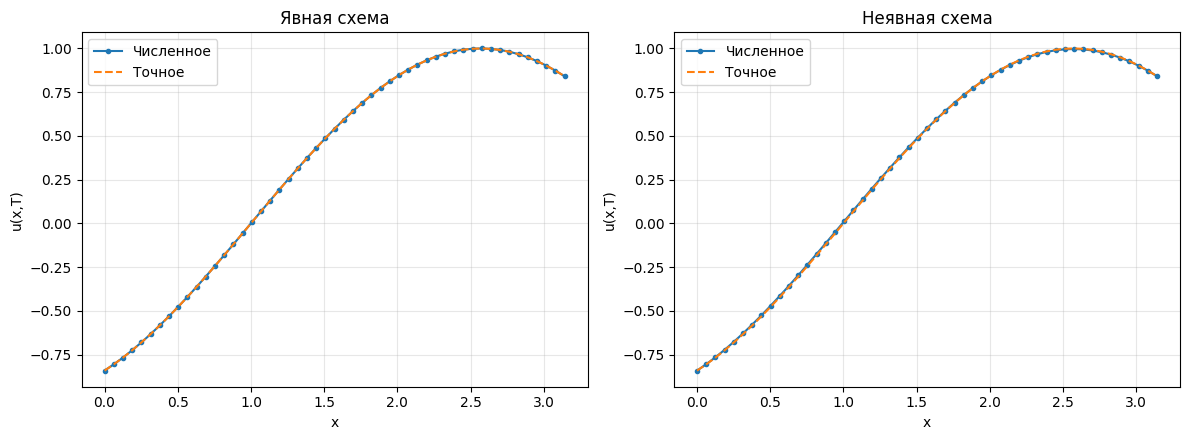

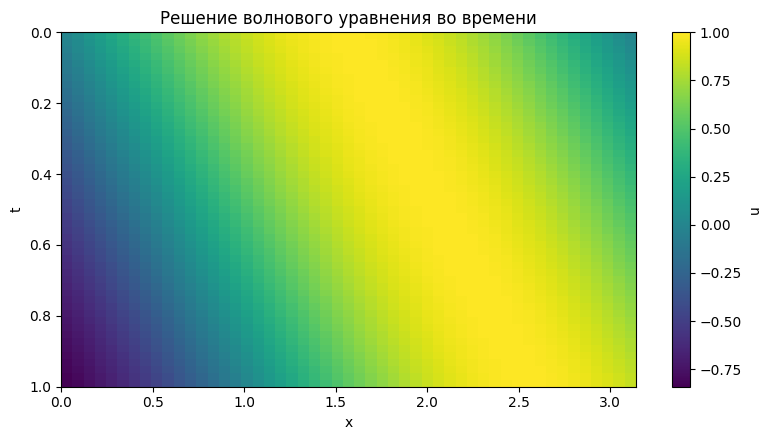


Графики сохранены: lab2_comparison.png, lab2_space_time.png

Исследование по пространственной сетке (второй порядок начального слоя):
explicit: Nx= 20, Nt=   8, h=0.15708, max error=1.392249e-03
implicit: Nx= 20, Nt=   8, h=0.15708, max error=3.866024e-02
explicit: Nx= 40, Nt=  16, h=0.07854, max error=3.632254e-04
implicit: Nx= 40, Nt=  16, h=0.07854, max error=2.143700e-02
explicit: Nx= 60, Nt=  24, h=0.05236, max error=1.645391e-04
implicit: Nx= 60, Nt=  24, h=0.05236, max error=1.479240e-02
explicit: Nx= 80, Nt=  32, h=0.03927, max error=9.308323e-05
implicit: Nx= 80, Nt=  32, h=0.03927, max error=1.128951e-02

Исследование по временному шагу (Nx=50):
explicit: Nt=  25, tau=0.04000, max error=1.987669e-04
implicit: Nt=  25, tau=0.04000, max error=1.425052e-02
explicit: Nt=  50, tau=0.02000, max error=1.553475e-04
implicit: Nt=  50, tau=0.02000, max error=7.408946e-03
explicit: Nt= 100, tau=0.01000, max error=1.473045e-04
implicit: Nt= 100, tau=0.01000, max error=3.805845e-03
expli

In [2]:
# -*- coding: utf-8 -*-
"""
ЛАБОРАТОРНАЯ РАБОТА № 2
Одномерное волновое уравнение. Вариант 1 из задания.

    u_tt = a^2 * u_xx,      0 < x < pi, 0 < t <= T
    u(0,t) = -sin(a*t)
    u(pi,t) =  sin(a*t)
    u(x,0) = sin(x)
    u_t(x,0) = -a*cos(x)

Точное решение: U(x,t) = sin(x-a*t).

Выполняются явная схема (схема "крест") и неявная схема.
Второе начальное условие аппроксимируется первым и вторым порядком.
Для варианта 1 в самом задании указаны значения u на концах отрезка,
то есть условия Дирихле. Поэтому в этой программе не вводятся фиктивные
варианты Неймана: используются именно граничные условия варианта 1.
"""

# ============================================================================
# БЛОК 1. ИМПОРТ БИБЛИОТЕК И ПАРАМЕТРЫ ЗАДАЧИ
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt

A_WAVE = 1.0
L = np.pi
T_FINAL = 1.0


# ============================================================================
# БЛОК 2. АНАЛИТИЧЕСКОЕ РЕШЕНИЕ И ГРАНИЧНЫЕ ЗНАЧЕНИЯ
# ============================================================================
def exact_solution(x, t, a=A_WAVE):
    """Точное решение, приведённое в варианте 1 задания."""
    return np.sin(x - a * t)


def left_boundary(t, a=A_WAVE):
    """Значение u(0,t) = -sin(a*t)."""
    return -np.sin(a * t)


def right_boundary(t, a=A_WAVE):
    """Значение u(pi,t) = sin(a*t)."""
    return np.sin(a * t)


# ============================================================================
# БЛОК 3. РЕШЕНИЕ ТРЁХДИАГОНАЛЬНОЙ СИСТЕМЫ МЕТОДОМ ПРОГОНКИ
# ============================================================================
def solve_tridiagonal(lower, diagonal, upper, rhs):
    """
    Решить трёхдиагональную систему методом прогонки (алгоритм Томаса).

    Система имеет вид:
      lower[i]*y[i-1] + diagonal[i]*y[i] + upper[i]*y[i+1] = rhs[i].

    Возвращается вектор y. Первый элемент нижней диагонали и последний
    элемент верхней диагонали не используются.
    """
    n = len(diagonal)
    if n == 0 or not (len(lower) == len(upper) == len(rhs) == n):
        raise ValueError("Неверные размеры трёхдиагональной системы.")

    # Прямой ход: выражаем y[i] через y[i+1].
    alpha = np.zeros(n, dtype=float)
    beta = np.zeros(n, dtype=float)
    denominator = diagonal[0]
    if abs(denominator) < 1e-14:
        raise ZeroDivisionError("Нулевой знаменатель в методе прогонки.")
    alpha[0] = -upper[0] / denominator if n > 1 else 0.0
    beta[0] = rhs[0] / denominator

    for i in range(1, n):
        denominator = diagonal[i] + lower[i] * alpha[i - 1]
        if abs(denominator) < 1e-14:
            raise ZeroDivisionError("Нулевой знаменатель в методе прогонки.")
        alpha[i] = -upper[i] / denominator if i < n - 1 else 0.0
        beta[i] = (rhs[i] - lower[i] * beta[i - 1]) / denominator

    # Обратный ход: восстанавливаем решение справа налево.
    solution = np.zeros(n, dtype=float)
    solution[-1] = beta[-1]
    for i in range(n - 2, -1, -1):
        solution[i] = alpha[i] * solution[i + 1] + beta[i]

    return solution


# ============================================================================
# БЛОК 4. ПОДГОТОВКА СЕТКИ И ПЕРВОГО ВРЕМЕННОГО СЛОЯ
# ============================================================================
def build_grid_and_initial_layer(a, length, final_time, nx, nt, init_order):
    """
    Создать сетки x и t и заполнить первые два временных слоя.

    Первое начальное условие задаёт u(x,0).
    Второе начальное условие задаёт скорость изменения решения u_t(x,0).

    Для слоя t=tau используем разложение Тейлора:
      u(x,tau) = u(x,0) + tau*u_t(x,0)
                 + tau^2/2*u_tt(x,0) + ...
    А из волнового уравнения u_tt(x,0)=a^2*u_xx(x,0).
    """
    if nx < 2 or nt < 1:
        raise ValueError("Требуется nx >= 2 и nt >= 1.")
    if init_order not in (1, 2):
        raise ValueError("init_order должен быть равен 1 или 2.")

    h = length / nx
    tau = final_time / nt
    x = np.linspace(0.0, length, nx + 1)
    t = np.linspace(0.0, final_time, nt + 1)

    u = np.zeros((nt + 1, nx + 1), dtype=float)
    u0 = np.sin(x)
    ut0 = -a * np.cos(x)
    u[0, :] = u0

    # Первый порядок: u^1 = u^0 + tau*u_t(x,0).
    u[1, 1:nx] = u0[1:nx] + tau * ut0[1:nx]

    if init_order == 2:
        # Второй порядок: добавляем tau^2/2 * u_tt(x,0).
        # Здесь u_xx(x,0) = -sin(x), поэтому u_tt=-a^2*sin(x).
        u[1, 1:nx] += 0.5 * tau**2 * (-a**2 * np.sin(x[1:nx]))

    # На первом слое границы задаются непосредственно из варианта 1.
    u[1, 0] = left_boundary(t[1], a)
    u[1, nx] = right_boundary(t[1], a)

    return x, t, u, h, tau


# ============================================================================
# БЛОК 5. ОСНОВНОЙ РЕШАТЕЛЬ ВОЛНОВОГО УРАВНЕНИЯ
# ============================================================================
def solve_hyperbolic(a=A_WAVE, length=L, final_time=T_FINAL,
                     nx=50, nt=50, scheme="explicit", init_order=2):
    """
    Решить волновое уравнение выбранной схемой.

    scheme='explicit' - явная схема "крест";
    scheme='implicit' - неявная схема с методом прогонки;
    init_order=1 или 2 - порядок аппроксимации второго начального условия.

    Возвращает x, t, u, где u[n,i] - решение в узле x[i] в момент t[n].
    """
    if scheme not in ("explicit", "implicit"):
        raise ValueError("scheme должен быть 'explicit' или 'implicit'.")

    x, t, u, h, tau = build_grid_and_initial_layer(
        a, length, final_time, nx, nt, init_order
    )

    # Число Куранта: r = a*tau/h.
    # Для явной схемы одномерного волнового уравнения нужно r <= 1.
    r = a * tau / h
    if scheme == "explicit" and r > 1.0 + 1e-12:
        raise ValueError(
            f"Нарушено условие устойчивости явной схемы: r={r:.5f}>1. "
            "Увеличьте nt или уменьшите nx."
        )
    r2 = r**2

    # Идём от известной пары слоёв n-1 и n к слою n+1.
    for n in range(1, nt):
        t_new = t[n + 1]

        if scheme == "explicit":
            # ------------------------------------------------------------
            # ЯВНАЯ СХЕМА "КРЕСТ"
            # u_i^(n+1) = 2u_i^n-u_i^(n-1)
            #             + r^2*(u_(i+1)^n-2u_i^n+u_(i-1)^n).
            # ------------------------------------------------------------
            u[n + 1, 1:nx] = (
                2.0 * u[n, 1:nx] - u[n - 1, 1:nx]
                + r2 * (u[n, 2:nx + 1] - 2.0 * u[n, 1:nx] + u[n, 0:nx - 1])
            )

            # Условия Дирихле на новом временном слое.
            u[n + 1, 0] = left_boundary(t_new, a)
            u[n + 1, nx] = right_boundary(t_new, a)

        else:
            # ------------------------------------------------------------
            # НЕЯВНАЯ СХЕМА
            # -r^2*u_(i-1)^(n+1) + (1+2r^2)*u_i^(n+1)
            # -r^2*u_(i+1)^(n+1) = 2u_i^n-u_i^(n-1).
            # Неизвестные нового слоя связаны в трёхдиагональную систему.
            # ------------------------------------------------------------
            number_of_unknowns = nx - 1
            lower = np.full(number_of_unknowns, -r2, dtype=float)
            diagonal = np.full(number_of_unknowns, 1.0 + 2.0 * r2, dtype=float)
            upper = np.full(number_of_unknowns, -r2, dtype=float)
            rhs = 2.0 * u[n, 1:nx] - u[n - 1, 1:nx]

            # Переносим известные граничные значения в правую часть.
            rhs[0] += r2 * left_boundary(t_new, a)
            rhs[-1] += r2 * right_boundary(t_new, a)

            # Решаем систему для всех внутренних узлов.
            u[n + 1, 1:nx] = solve_tridiagonal(lower, diagonal, upper, rhs)

            # Граничные значения заданы прямо в условии варианта 1.
            u[n + 1, 0] = left_boundary(t_new, a)
            u[n + 1, nx] = right_boundary(t_new, a)

    return x, t, u


# ============================================================================
# БЛОК 6. СРАВНЕНИЕ С АНАЛИТИЧЕСКИМ РЕШЕНИЕМ
# ============================================================================
def compute_error(x, t, u_numerical, a=A_WAVE):
    """Вернуть матрицу абсолютных ошибок |u_num-U_exact| на всей сетке."""
    exact = np.array([exact_solution(x, tn, a) for tn in t])
    return np.abs(u_numerical - exact), exact


def print_errors_at_times(t, error):
    """Показать максимальную по пространству ошибку в выбранные моменты времени."""
    print("Погрешность в выбранные моменты времени:")
    for fraction in (0.0, 0.25, 0.5, 0.75, 1.0):
        n = int(round(fraction * (len(t) - 1)))
        print(f"  t={t[n]:.4f}: max_x error={np.max(error[n, :]):.6e}")


# ============================================================================
# БЛОК 7. ИССЛЕДОВАНИЕ ВЛИЯНИЯ ПРОСТРАНСТВЕННОГО И ВРЕМЕННОГО ШАГОВ
# ============================================================================
def convergence_study():
    """Проверить изменение ошибки при измельчении h и tau для двух схем."""
    print("\nИсследование по пространственной сетке (второй порядок начального слоя):")
    for nx in (20, 40, 60, 80):
        # Для явной схемы выбираем nt так, чтобы число Куранта было около 0.8.
        nt = max(1, int(np.ceil(A_WAVE * T_FINAL * nx / (0.8 * L))))
        for scheme in ("explicit", "implicit"):
            x, t, u = solve_hyperbolic(nx=nx, nt=nt, scheme=scheme, init_order=2)
            error, _ = compute_error(x, t, u)
            print(f"{scheme:8s}: Nx={nx:3d}, Nt={nt:4d}, h={L/nx:.5f}, max error={np.max(error):.6e}")

    print("\nИсследование по временному шагу (Nx=50):")
    nx = 50
    for nt in (25, 50, 100, 200, 400):
        for scheme in ("explicit", "implicit"):
            x, t, u = solve_hyperbolic(nx=nx, nt=nt, scheme=scheme, init_order=2)
            error, _ = compute_error(x, t, u)
            print(f"{scheme:8s}: Nt={nt:4d}, tau={T_FINAL/nt:.5f}, max error={np.max(error):.6e}")


# ============================================================================
# БЛОК 8. ГЛАВНЫЙ ЗАПУСК: ДВЕ СХЕМЫ И ДВА ПОРЯДКА НАЧАЛЬНОГО УСЛОВИЯ
# ============================================================================
def main():
    nx, nt = 50, 50
    all_results = {}

    print("Лабораторная работа № 2. Вариант 1")
    print("Уравнение: u_tt = a^2*u_xx; точное решение: sin(x-a*t)")
    print(f"a={A_WAVE}, L=pi, T={T_FINAL}, Nx={nx}, Nt={nt}")
    print(f"Число Куранта r={A_WAVE*(T_FINAL/nt)/(L/nx):.5f}\n")

    # Проверяем обе схемы и оба способа старта временного процесса.
    for scheme in ("explicit", "implicit"):
        for init_order in (1, 2):
            x, t, u = solve_hyperbolic(
                nx=nx, nt=nt, scheme=scheme, init_order=init_order
            )
            error, exact = compute_error(x, t, u)
            all_results[(scheme, init_order)] = (x, t, u, error, exact)
            print(
                f"{scheme:8s}, порядок начального условия={init_order}: "
                f"max error={np.max(error):.6e}"
            )
            print_errors_at_times(t, error)

    # График решения при t=T для явной и неявной схемы (порядок старта 2).
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, scheme in zip(axes, ("explicit", "implicit")):
        x, t, u, error, exact = all_results[(scheme, 2)]
        ax.plot(x, u[-1, :], label="Численное", marker="o", ms=3)
        ax.plot(x, exact[-1, :], "--", label="Точное")
        ax.set_title("Явная схема" if scheme == "explicit" else "Неявная схема")
        ax.set_xlabel("x")
        ax.set_ylabel("u(x,T)")
        ax.grid(True, alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig("lab2_comparison.png", dpi=150)
    plt.show()
    # Карта изменения решения со временем для явной схемы.
    x, t, u, _, _ = all_results[("explicit", 2)]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    image = ax.imshow(u, aspect="auto", extent=[0, L, T_FINAL, 0], cmap="viridis")
    ax.set_xlabel("x")
    ax.set_ylabel("t")
    ax.set_title("Решение волнового уравнения во времени")
    fig.colorbar(image, ax=ax, label="u")
    fig.tight_layout()
    fig.savefig("lab2_space_time.png", dpi=150)
    plt.show()
    print("\nГрафики сохранены: lab2_comparison.png, lab2_space_time.png")

    return all_results


# ============================================================================
# БЛОК 9. ТОЧКА ВХОДА
# ============================================================================
if __name__ == "__main__":
    main()
    convergence_study()

ЛР 3


Сравнение итерационных методов
Сетка: nx=20, ny=20; tol=1e-08
jacobi  : итераций=  1172, max error=7.991e-07, RMS error=3.805e-07
seidel  : итераций=   618, max error=3.913e-07, RMS error=1.871e-07
sor     : итераций=    77, max error=9.881e-09, RMS error=3.809e-09


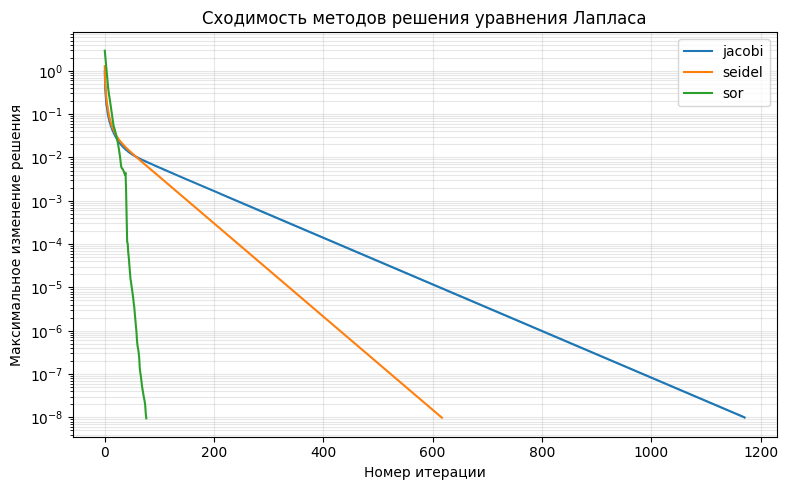


Визуализация sor: итераций=77, max error=9.881e-09, RMS error=3.809e-09


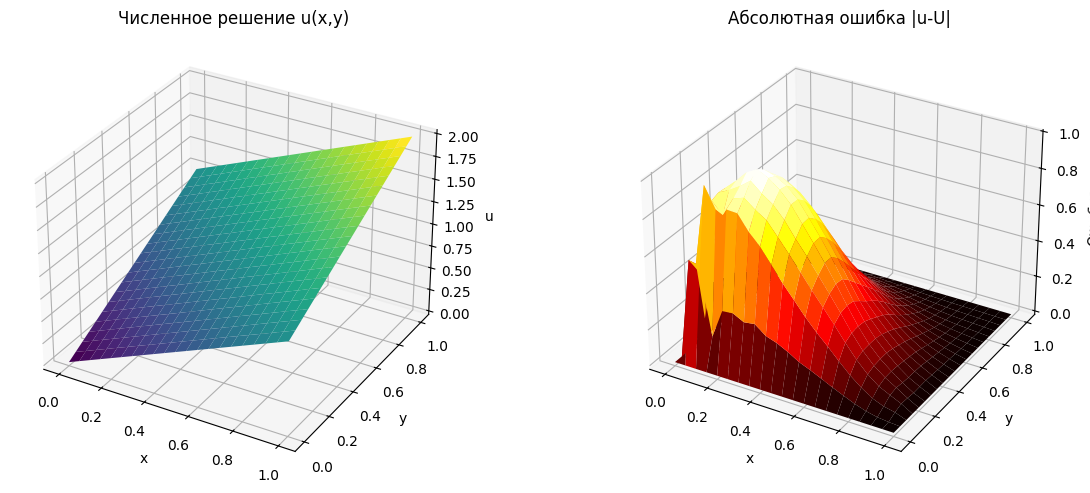


Зависимость ошибки от сетки, метод sor
N=  5, h=0.20000, max error=9.328e-12, RMS error=3.351e-12, iterations=23
N= 10, h=0.10000, max error=7.076e-11, RMS error=2.412e-11, iterations=46
N= 20, h=0.05000, max error=2.048e-10, RMS error=7.444e-11, iterations=90
N= 40, h=0.02500, max error=4.474e-10, RMS error=1.722e-10, iterations=176
N= 80, h=0.01250, max error=1.192e-09, RMS error=4.276e-10, iterations=341


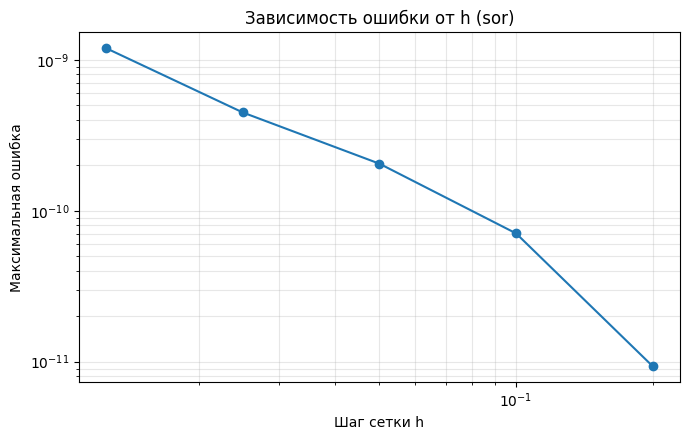


Количество итераций в зависимости от размера сетки
jacobi  : N=5: 82, N=10: 318, N=20: 1172, N=40: 4252
seidel  : N=5: 45, N=10: 168, N=20: 618, N=40: 2245
sor     : N=5: 19, N=10: 38, N=20: 77, N=40: 160


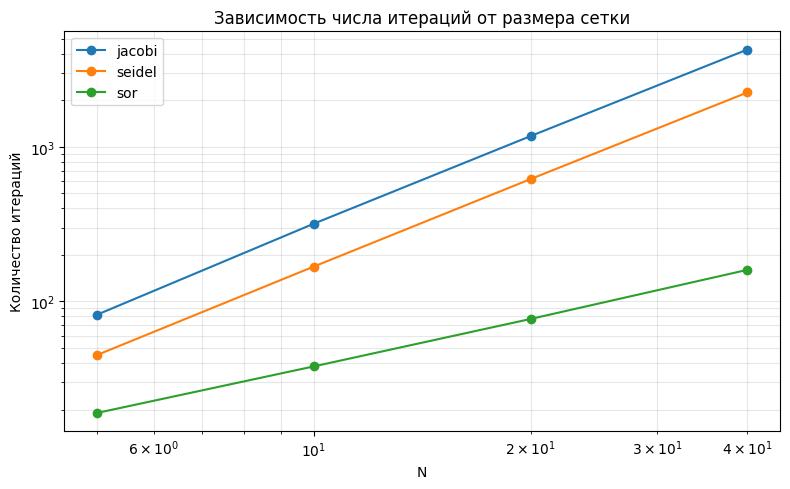


Итог по сетке 20x20:
jacobi  : итераций=  1172, max error=7.991e-07, RMS error=3.805e-07
seidel  : итераций=   618, max error=3.913e-07, RMS error=1.871e-07
sor     : итераций=    77, max error=9.881e-09, RMS error=3.809e-09

Созданы файлы:
  lab3_convergence.png
  lab3_solution_and_error.png
  lab3_iterations_vs_n.png
  lab3_error_vs_h.png


In [3]:
# -*- coding: utf-8 -*-
"""
ЛАБОРАТОРНАЯ РАБОТА № 3
Решение краевой задачи для эллиптического уравнения.
Вариант 1 из задания:

    u_xx + u_yy = 0,       0 < x < 1, 0 < y < 1
    u(0,y) = y
    u(1,y) = 1+y
    u(x,0) = x
    u(x,1) = 1+x

Точное решение: U(x,y)=x+y.

Дискретная задача решается тремя итерационными методами:
  1) простые итерации (Якоби / Либмана);
  2) метод Зейделя;
  3) метод верхней релаксации (SOR).

Важное исправление по сравнению с исходником: метод Якоби теперь действительно
использует только значения предыдущей итерации. В исходном коде массив
перезаписывался сразу, поэтому "jacobi" фактически работал как метод Зейделя.
Также добавлена корректная формула для прямоугольной сетки hx != hy.
"""

# ============================================================================
# БЛОК 1. БИБЛИОТЕКИ И НАСТРОЙКИ ЗАДАЧИ
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt

X_LEFT, X_RIGHT = 0.0, 1.0
Y_BOTTOM, Y_TOP = 0.0, 1.0


# ============================================================================
# БЛОК 2. ТОЧНОЕ РЕШЕНИЕ И ГРАНИЧНЫЕ УСЛОВИЯ
# ============================================================================
def exact_solution(X, Y):
    """Точное решение варианта 1: U(x,y)=x+y."""
    return X + Y


def apply_boundary_conditions(u, x, y):
    """
    Записать значения функции на четырёх сторонах квадрата.

    Внутри массива u[i,j]:
      i отвечает за координату x;
      j отвечает за координату y.
    """
    u[0, :] = y                    # левая сторона: u(0,y)=y
    u[-1, :] = 1.0 + y             # правая сторона: u(1,y)=1+y
    u[:, 0] = x                    # нижняя сторона: u(x,0)=x
    u[:, -1] = 1.0 + x             # верхняя сторона: u(x,1)=1+x

    # В углах два граничных условия должны давать одно и то же число.
    # Для варианта 1 они согласованы, поэтому порядок присваивания не меняет ответ.


# ============================================================================
# БЛОК 3. ФОРМУЛА ДЛЯ ОДНОГО ВНУТРЕННЕГО УЗЛА
# ============================================================================
def laplace_update(u, i, j, hx, hy):
    """
    Вычислить новое значение в узле (i,j) из пятиузловой разностной схемы.

    При hx=hy это обычное среднее четырёх соседей.
    При hx != hy соседние значения взвешиваются с учётом разных шагов.

    Формула:
      u[i,j] = ((u[i-1,j]+u[i+1,j])/hx^2
              + (u[i,j-1]+u[i,j+1])/hy^2)
               / (2/hx^2 + 2/hy^2).
    """
    wx = 1.0 / hx**2
    wy = 1.0 / hy**2
    return (
        wx * (u[i - 1, j] + u[i + 1, j])
        + wy * (u[i, j - 1] + u[i, j + 1])
    ) / (2.0 * (wx + wy))


# ============================================================================
# БЛОК 4. ОСНОВНОЙ ИТЕРАЦИОННЫЙ РЕШАТЕЛЬ
# ============================================================================
def solve_elliptic(nx=20, ny=20, tol=1e-8, max_iter=100000,
                   method="sor", omega=None):
    """
    Решить уравнение Лапласа одним из трёх итерационных методов.

    nx, ny   - количество отрезков сетки по x и y;
    tol      - остановка, когда максимальное изменение за итерацию меньше tol;
    max_iter - максимальное количество итераций;
    method   - 'jacobi', 'seidel' или 'sor';
    omega    - коэффициент релаксации для SOR (0 < omega < 2).

    Возвращаются координатные сетки, численное и точное решения,
    число итераций и история максимальных изменений.
    """
    if nx < 2 or ny < 2:
        raise ValueError("Для внутреннего узла требуется nx >= 2 и ny >= 2.")
    if tol <= 0 or max_iter < 1:
        raise ValueError("tol должен быть положительным, max_iter >= 1.")
    if method not in ("jacobi", "seidel", "sor"):
        raise ValueError("method должен быть 'jacobi', 'seidel' или 'sor'.")

    # ------------------------------------------------------------
    # 4.1. Построение равномерной сетки
    # ------------------------------------------------------------
    x = np.linspace(X_LEFT, X_RIGHT, nx + 1)
    y = np.linspace(Y_BOTTOM, Y_TOP, ny + 1)
    hx = (X_RIGHT - X_LEFT) / nx
    hy = (Y_TOP - Y_BOTTOM) / ny
    X, Y = np.meshgrid(x, y, indexing="ij")

    # ------------------------------------------------------------
    # 4.2. Начальное приближение и граничные значения
    # ------------------------------------------------------------
    u = np.zeros((nx + 1, ny + 1), dtype=float)
    apply_boundary_conditions(u, x, y)
    U_exact = exact_solution(X, Y)

    # ------------------------------------------------------------
    # 4.3. Подбор параметра релаксации для метода SOR
    # ------------------------------------------------------------
    if method == "sor":
        if omega is None:
            # Оценка оптимального omega для прямоугольной равномерной сетки.
            # Для квадратной сетки nx=ny=N получается классическая формула
            # omega=2/(1+sin(pi/N)).
            wx = 1.0 / hx**2
            wy = 1.0 / hy**2
            rho_j = (
                wx * np.cos(np.pi / nx) + wy * np.cos(np.pi / ny)
            ) / (wx + wy)
            omega = min(1.999999, 2.0 / (1.0 + np.sqrt(max(0.0, 1.0 - rho_j**2))))
        if not (0.0 < omega < 2.0):
            raise ValueError("Для SOR необходимо 0 < omega < 2.")
    else:
        omega = 1.0

    # ------------------------------------------------------------
    # 4.4. Главный итерационный цикл
    # ------------------------------------------------------------
    changes = []
    converged = False

    for iteration in range(1, max_iter + 1):
        # Сохраняем предыдущее приближение для оценки изменения.
        old = u.copy()

        if method == "jacobi":
            # МЕТОД ЯКОБИ:
            # каждое новое значение считается только по массиву old.
            # Ни одно значение текущей итерации не используется раньше времени.
            new = old.copy()
            for i in range(1, nx):
                for j in range(1, ny):
                    new[i, j] = laplace_update(old, i, j, hx, hy)
            u = new

        elif method == "seidel":
            # МЕТОД ЗЕЙДЕЛЯ:
            # обновляем массив u прямо во время обхода сетки.
            # Поэтому часть соседей уже относится к новой итерации,
            # а часть - ещё к старой. Это ускоряет сходимость по сравнению с Якоби.
            for i in range(1, nx):
                for j in range(1, ny):
                    u[i, j] = laplace_update(u, i, j, hx, hy)

        elif method == "sor":
            # МЕТОД ВЕРХНЕЙ РЕЛАКСАЦИИ:
            # сначала вычисляем значение, как в методе Зейделя,
            # затем делаем шаг omega раз больше обычного изменения.
            for i in range(1, nx):
                for j in range(1, ny):
                    gauss_seidel_value = laplace_update(u, i, j, hx, hy)
                    u[i, j] = (
                        (1.0 - omega) * u[i, j]
                        + omega * gauss_seidel_value
                    )

        # Измеряем, насколько изменилось решение за одну итерацию.
        max_change = float(np.max(np.abs(u - old)))
        changes.append(max_change)

        # Если изменения стали меньше заданного допуска, останавливаемся.
        if max_change < tol:
            converged = True
            break

    if not converged:
        print(f"Предупреждение: {method} не достиг допуска {tol:g} за {max_iter} итераций.")

    return X, Y, u, U_exact, iteration, changes


# ============================================================================
# БЛОК 5. ОЦЕНКА ОШИБКИ ЧИСЛЕННОГО РЕШЕНИЯ
# ============================================================================
def compute_error(numerical, exact):
    """Вернуть максимальную и среднеквадратичную абсолютные ошибки."""
    error = np.abs(numerical - exact)
    max_error = float(np.max(error))
    rms_error = float(np.sqrt(np.mean(error**2)))
    return max_error, rms_error, error


# ============================================================================
# БЛОК 6. СРАВНЕНИЕ МЕТОДОВ ЯКОБИ, ЗЕЙДЕЛЯ И SOR
# ============================================================================
def compare_methods(nx=20, ny=20, tol=1e-8, make_plot=True):
    """Запустить три итерационных метода на одной и той же сетке."""
    methods = ("jacobi", "seidel", "sor")
    results = {}

    print("\nСравнение итерационных методов")
    print(f"Сетка: nx={nx}, ny={ny}; tol={tol:g}")
    for method in methods:
        X, Y, u, exact, iterations, changes = solve_elliptic(
            nx=nx, ny=ny, tol=tol, method=method
        )
        max_error, rms_error, error = compute_error(u, exact)
        results[method] = {
            "X": X, "Y": Y, "u": u, "exact": exact, "error": error,
            "iterations": iterations, "changes": changes,
            "max_error": max_error, "rms_error": rms_error,
        }
        print(
            f"{method:8s}: итераций={iterations:6d}, "
            f"max error={max_error:.3e}, RMS error={rms_error:.3e}"
        )

    # График показывает уменьшение максимального изменения от итерации к итерации.
    if make_plot:
        fig, ax = plt.subplots(figsize=(8, 5))
        for method in methods:
            ax.semilogy(results[method]["changes"], label=method)
        ax.set_xlabel("Номер итерации")
        ax.set_ylabel("Максимальное изменение решения")
        ax.set_title("Сходимость методов решения уравнения Лапласа")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig("lab3_convergence.png", dpi=150)
        plt.show()
    return results


# ============================================================================
# БЛОК 7. РИСУНОК ЧИСЛЕННОГО РЕШЕНИЯ И ОШИБКИ
# ============================================================================
def visualize_solution(nx=20, ny=20, method="sor"):
    """Построить поверхности численного решения и абсолютной ошибки."""
    X, Y, u, exact, iterations, _ = solve_elliptic(
        nx=nx, ny=ny, method=method
    )
    max_error, rms_error, error = compute_error(u, exact)
    print(
        f"\nВизуализация {method}: итераций={iterations}, "
        f"max error={max_error:.3e}, RMS error={rms_error:.3e}"
    )

    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(1, 2, 1, projection="3d")
    ax1.plot_surface(X, Y, u, cmap="viridis", edgecolor="none")
    ax1.set_title("Численное решение u(x,y)")
    ax1.set_xlabel("x")
    ax1.set_ylabel("y")
    ax1.set_zlabel("u")

    ax2 = fig.add_subplot(1, 2, 2, projection="3d")
    ax2.plot_surface(X, Y, error, cmap="hot", edgecolor="none")
    ax2.set_title("Абсолютная ошибка |u-U|")
    ax2.set_xlabel("x")
    ax2.set_ylabel("y")
    ax2.set_zlabel("Ошибка")

    fig.tight_layout()
    fig.savefig("lab3_solution_and_error.png", dpi=150)
    plt.show()
# ============================================================================
# БЛОК 8. ИССЛЕДОВАНИЕ СЕТКИ И КОЛИЧЕСТВА ИТЕРАЦИЙ
# ============================================================================
def study_grid_dependence(method="sor", tol=1e-10):
    """
    Повторить расчёт на сетках разной плотности.

    Для варианта U=x+y центральная разностная схема воспроизводит линейное
    решение очень точно. Поэтому ошибка здесь в основном связана с допуском
    итераций и машинным округлением, а не с погрешностью аппроксимации.
    """
    print(f"\nЗависимость ошибки от сетки, метод {method}")
    rows = []
    for n in (5, 10, 20, 40, 80):
        X, Y, u, exact, iterations, _ = solve_elliptic(
            nx=n, ny=n, tol=tol, method=method
        )
        max_error, rms_error, _ = compute_error(u, exact)
        h = 1.0 / n
        rows.append((h, max_error, rms_error, iterations))
        print(
            f"N={n:3d}, h={h:.5f}, max error={max_error:.3e}, "
            f"RMS error={rms_error:.3e}, iterations={iterations}"
        )

    # Рисуем изменение максимальной ошибки при уменьшении шага h.
    hs = np.array([row[0] for row in rows])
    errors = np.array([row[1] for row in rows])
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.loglog(hs, np.maximum(errors, 1e-16), "o-")
    ax.set_xlabel("Шаг сетки h")
    ax.set_ylabel("Максимальная ошибка")
    ax.set_title(f"Зависимость ошибки от h ({method})")
    ax.grid(True, which="both", alpha=0.3)
    fig.tight_layout()
    fig.savefig("lab3_error_vs_h.png", dpi=150)
    plt.show()
    return rows


def study_iterations_vs_n(methods=("jacobi", "seidel", "sor"),
                          n_values=(5, 10, 20, 40), tol=1e-8):
    """Сравнить, сколько итераций нужно каждому методу на разных сетках."""
    fig, ax = plt.subplots(figsize=(8, 5))
    print("\nКоличество итераций в зависимости от размера сетки")
    for method in methods:
        counts = []
        for n in n_values:
            *_, iterations, _ = solve_elliptic(
                nx=n, ny=n, tol=tol, method=method
            )
            counts.append(iterations)
        print(f"{method:8s}: " + ", ".join(
            f"N={n}: {count}" for n, count in zip(n_values, counts)
        ))
        ax.loglog(n_values, counts, "o-", label=method)

    ax.set_xlabel("N")
    ax.set_ylabel("Количество итераций")
    ax.set_title("Зависимость числа итераций от размера сетки")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig("lab3_iterations_vs_n.png", dpi=150)
    plt.show()
# ============================================================================
# БЛОК 9. ГЛАВНЫЙ ЗАПУСК ПРОГРАММЫ
# ============================================================================
def main():
    """Выполнить все основные расчёты и сохранить графики."""
    results = compare_methods(nx=20, ny=20, tol=1e-8, make_plot=True)
    visualize_solution(nx=20, ny=20, method="sor")
    study_grid_dependence(method="sor", tol=1e-10)
    study_iterations_vs_n()

    print("\nИтог по сетке 20x20:")
    for method, result in results.items():
        print(
            f"{method:8s}: итераций={result['iterations']:6d}, "
            f"max error={result['max_error']:.3e}, "
            f"RMS error={result['rms_error']:.3e}"
        )
    print("\nСозданы файлы:")
    print("  lab3_convergence.png")
    print("  lab3_solution_and_error.png")
    print("  lab3_iterations_vs_n.png")
    print("  lab3_error_vs_h.png")


# ============================================================================
# БЛОК 10. ТОЧКА ВХОДА
# ============================================================================
if __name__ == "__main__":
    main()

ЛР 4

In [4]:
# -*- coding: utf-8 -*-
"""
ЛАБОРАТОРНАЯ РАБОТА № 4
Двумерное уравнение теплопроводности. Задача 1, вариант 1:

    u_t = a*(u_xx + u_yy),       0<x<pi, 0<y<pi, 0<t<=T
    u(0,y,t)  = cos(y)*exp(-2*a*t)
    u(pi,y,t) = -cos(y)*exp(-2*a*t)
    u(x,0,t)  = cos(x)*exp(-2*a*t)
    u(x,pi,t) = -cos(x)*exp(-2*a*t)
    u(x,y,0)  = cos(x)*cos(y)

Точное решение: U(x,y,t)=cos(x)*cos(y)*exp(-2*a*t).

Реализованы:
  1) схема переменных направлений Писмена - Рекфорда (ADI);
  2) метод дробных шагов (последовательное неявное решение по x и y).

Главное исправление по сравнению с исходником: в промежуточном слое
схемы Писмена - Рекфорда граничные значения задаются на половинном моменте
времени t_n+tau/2, а не на t_n+tau. Также приведены в порядок проверка
шагов времени, прогонка и комментарии к каждому блоку.
"""

# ============================================================================
# БЛОК 1. БИБЛИОТЕКИ И ПАРАМЕТРЫ ЗАДАЧИ
# ============================================================================
import numpy as np
import matplotlib
matplotlib.use("Agg")  # сохраняем графики в файлы без открытия окон
import matplotlib.pyplot as plt

A_DIFFUSION = 1.0
M1, M2 = 1, 1
LX, LY = np.pi, np.pi
T_FINAL = 0.1


# ============================================================================
# БЛОК 2. ТОЧНОЕ РЕШЕНИЕ И ЧЕТЫРЕ ГРАНИЧНЫХ УСЛОВИЯ
# ============================================================================
def exact_solution(x, y, t):
    """Точное решение задачи 1: cos(m1*x)*cos(m2*y)*exp(-(m1²+m2²)*a*t)."""
    return (
        np.cos(M1 * x) * np.cos(M2 * y)
        * np.exp(-(M1**2 + M2**2) * A_DIFFUSION * t)
    )


def boundary_left(y, t):
    """Значения на левой стороне x=0."""
    return np.cos(M2 * y) * np.exp(-(M1**2 + M2**2) * A_DIFFUSION * t)


def boundary_right(y, t):
    """Значения на правой стороне x=pi."""
    return (-1)**M1 * np.cos(M2 * y) * np.exp(-(M1**2 + M2**2) * A_DIFFUSION * t)


def boundary_bottom(x, t):
    """Значения на нижней стороне y=0."""
    return np.cos(M1 * x) * np.exp(-(M1**2 + M2**2) * A_DIFFUSION * t)


def boundary_top(x, t):
    """Значения на верхней стороне y=pi."""
    return (-1)**M2 * np.cos(M1 * x) * np.exp(-(M1**2 + M2**2) * A_DIFFUSION * t)


def apply_all_boundaries(U, x, y, t):
    """Заполнить значения U на всех четырёх сторонах прямоугольной сетки."""
    U[0, :] = boundary_left(y, t)
    U[-1, :] = boundary_right(y, t)
    U[:, 0] = boundary_bottom(x, t)
    U[:, -1] = boundary_top(x, t)
    # В углах два граничных условия встречаются. В варианте 1 они согласованы.


# ============================================================================
# БЛОК 3. СОЗДАНИЕ СЕТКИ И ПРОВЕРКА ВРЕМЕННОГО ШАГА
# ============================================================================
def make_grid(nx, ny, tau, final_time=T_FINAL):
    """
    Создать координатные сетки и временную сетку.

    Для простоты и точного попадания в конечное время требуем, чтобы
    final_time/tau было целым числом (с небольшой погрешностью округления).
    """
    if nx < 2 or ny < 2 or tau <= 0 or final_time <= 0:
        raise ValueError("Нужно nx>=2, ny>=2, tau>0 и final_time>0.")

    steps_real = final_time / tau
    nt = int(round(steps_real))
    if nt < 1 or not np.isclose(steps_real, nt, rtol=1e-10, atol=1e-10):
        raise ValueError("Выберите tau так, чтобы final_time/tau было целым числом.")

    # Шаги и координаты по двум пространственным направлениям.
    hx = LX / nx
    hy = LY / ny
    x = np.linspace(0.0, LX, nx + 1)
    y = np.linspace(0.0, LY, ny + 1)
    t = np.linspace(0.0, final_time, nt + 1)
    return x, y, t, hx, hy, nt


# ============================================================================
# БЛОК 4. МЕТОД ПРОГОНКИ ДЛЯ ТРЁХДИАГОНАЛЬНОЙ СИСТЕМЫ
# ============================================================================
def solve_tridiagonal(lower, diagonal, upper, rhs):
    """
    Решить трёхдиагональную систему методом прогонки (алгоритм Томаса).

    На каждом шаге прямого хода уравнение преобразуется к виду:
        v[i] = alpha[i]*v[i+1] + beta[i].
    После прямого хода выполняется обратный ход справа налево.

    lower, diagonal, upper - три диагонали матрицы;
    rhs - правая часть.
    """
    n = len(rhs)
    if n == 0 or not (len(lower) == len(diagonal) == len(upper) == n):
        raise ValueError("Неверный размер трёхдиагональной системы.")

    alpha = np.zeros(n, dtype=float)
    beta = np.zeros(n, dtype=float)

    # ------------------------------------------------------------
    # Прямой ход прогонки
    # ------------------------------------------------------------
    denominator = diagonal[0]
    if abs(denominator) < 1e-14:
        raise ZeroDivisionError("Нулевой знаменатель на первом шаге прогонки.")
    alpha[0] = -upper[0] / denominator if n > 1 else 0.0
    beta[0] = rhs[0] / denominator

    for i in range(1, n):
        denominator = diagonal[i] + lower[i] * alpha[i - 1]
        if abs(denominator) < 1e-14:
            raise ZeroDivisionError(f"Нулевой знаменатель на шаге прогонки i={i}.")
        alpha[i] = -upper[i] / denominator if i < n - 1 else 0.0
        beta[i] = (rhs[i] - lower[i] * beta[i - 1]) / denominator

    # ------------------------------------------------------------
    # Обратный ход прогонки
    # ------------------------------------------------------------
    solution = np.zeros(n, dtype=float)
    solution[-1] = beta[-1]
    for i in range(n - 2, -1, -1):
        solution[i] = alpha[i] * solution[i + 1] + beta[i]

    return solution


# ============================================================================
# БЛОК 5. ВСПОМОГАТЕЛЬНОЕ РЕШЕНИЕ СИСТЕМ ВДОЛЬ ОДНОЙ КООРДИНАТЫ
# ============================================================================
def solve_x_line(rhs_line, y_value, t_boundary, hx, nx, coefficient):
    """
    Решить одну строку неизвестных по x при фиксированном y.

    Уравнение имеет вид:
      -q*u_(i-1) + (1+2q)*u_i - q*u_(i+1) = rhs_i.

    Граничные значения по x известны и переносятся в правую часть.
    coefficient обычно равен a*tau/(2*hx^2) для схемы Писмена - Рекфорда
    или a*tau/hx^2 для метода дробных шагов.
    """
    q = coefficient
    lower = np.full(nx - 1, -q, dtype=float)
    diagonal = np.full(nx - 1, 1.0 + 2.0 * q, dtype=float)
    upper = np.full(nx - 1, -q, dtype=float)
    rhs = np.asarray(rhs_line, dtype=float).copy()

    # Известные u(0,y,t) и u(pi,y,t) переносятся в правую часть.
    left_value = boundary_left(y_value, t_boundary)
    right_value = boundary_right(y_value, t_boundary)
    rhs[0] -= lower[0] * left_value
    rhs[-1] -= upper[-1] * right_value

    return solve_tridiagonal(lower, diagonal, upper, rhs)


def solve_y_line(rhs_line, x_value, t_boundary, hy, ny, coefficient):
    """
    Решить один столбец неизвестных по y при фиксированном x.

    Граничные значения снизу и сверху задаются условиями варианта 1.
    """
    q = coefficient
    lower = np.full(ny - 1, -q, dtype=float)
    diagonal = np.full(ny - 1, 1.0 + 2.0 * q, dtype=float)
    upper = np.full(ny - 1, -q, dtype=float)
    rhs = np.asarray(rhs_line, dtype=float).copy()

    bottom_value = boundary_bottom(x_value, t_boundary)
    top_value = boundary_top(x_value, t_boundary)
    rhs[0] -= lower[0] * bottom_value
    rhs[-1] -= upper[-1] * top_value

    return solve_tridiagonal(lower, diagonal, upper, rhs)


# ============================================================================
# БЛОК 6. СХЕМА ПЕРЕМЕННЫХ НАПРАВЛЕНИЙ ПИСМЕНА - РЕКФОРДА (ADI)
# ============================================================================
def solve_peaceman_rachford(nx, ny, tau, initial=None, final_time=T_FINAL, return_history=False):
    """
    Решить двумерное уравнение схемой переменных направлений Писмена - Рекфорда.

    Каждый полный временной шаг состоит из двух полушагов:
      1) неявное решение по x и явное по y;
      2) явное решение по x и неявное по y.

    В промежуточном слое границы должны соответствовать t_n+tau/2.
    В исходном коде они ставились на t_n+tau; это исправлено.
    """
    x, y, t, hx, hy, nt = make_grid(nx, ny, tau, final_time)
    X, Y = np.meshgrid(x, y, indexing="ij")

    # Начальное распределение температуры при t=0.
    if initial is None:
        U = exact_solution(X, Y, 0.0)
    else:
        U = np.asarray(initial, dtype=float).copy()
    if U.shape != (nx + 1, ny + 1):
        raise ValueError("Размер initial не совпадает с размером сетки.")
    apply_all_boundaries(U, x, y, 0.0)

    U_half = np.empty_like(U)
    U_next = np.empty_like(U)
    history = np.empty((nt + 1, nx + 1, ny + 1), dtype=float)
    history[0] = U

    # Коэффициенты половинного шага в направлениях x и y.
    qx = A_DIFFUSION * tau / (2.0 * hx**2)
    qy = A_DIFFUSION * tau / (2.0 * hy**2)

    for n in range(nt):
        t_half = 0.5 * (t[n] + t[n + 1])
        t_next = t[n + 1]

        # --------------------------------------------------------
        # Первый полушаг: (I - tau/2*A_x) U_half = (I + tau/2*A_y) U_old.
        # Для каждой фиксированной строки y решается система по x.
        # --------------------------------------------------------
        apply_all_boundaries(U_half, x, y, t_half)
        for j in range(1, ny):
            rhs = (
                U[1:nx, j]
                + qy * (U[1:nx, j + 1] - 2.0 * U[1:nx, j] + U[1:nx, j - 1])
            )
            U_half[1:nx, j] = solve_x_line(
                rhs, y[j], t_half, hx, nx, qx
            )

        # --------------------------------------------------------
        # Второй полушаг: (I - tau/2*A_y) U_next = (I + tau/2*A_x) U_half.
        # Для каждого фиксированного x решается система по y.
        # --------------------------------------------------------
        apply_all_boundaries(U_next, x, y, t_next)
        for i in range(1, nx):
            rhs = (
                U_half[i, 1:ny]
                + qx * (U_half[i + 1, 1:ny] - 2.0 * U_half[i, 1:ny] + U_half[i - 1, 1:ny])
            )
            U_next[i, 1:ny] = solve_y_line(
                rhs, x[i], t_next, hy, ny, qy
            )

        # Переходим к следующему временному шагу.
        apply_all_boundaries(U_next, x, y, t_next)
        U[:, :] = U_next
        history[n + 1] = U

    if return_history:
        return x, y, history
    return x, y, U


# ============================================================================
# БЛОК 7. МЕТОД ДРОБНЫХ ШАГОВ (ЯНЕНКО)
# ============================================================================
def solve_fractional_steps(nx, ny, tau, initial=None, final_time=T_FINAL, return_history=False):
    """
    Решить двумерное уравнение методом дробных шагов (последовательное расщепление).

    Один полный временной шаг разбивается на два последовательных действия:
      1) решается неявная задача только по x;
      2) решается неявная задача только по y.

    В отличие от схемы Писмена - Рекфорда, здесь каждый одномерный шаг
    использует полный tau. Метод расщепления такого типа имеет первый порядок
    по времени в общем случае.
    """
    x, y, t, hx, hy, nt = make_grid(nx, ny, tau, final_time)
    X, Y = np.meshgrid(x, y, indexing="ij")

    if initial is None:
        U = exact_solution(X, Y, 0.0)
    else:
        U = np.asarray(initial, dtype=float).copy()
    if U.shape != (nx + 1, ny + 1):
        raise ValueError("Размер initial не совпадает с размером сетки.")
    apply_all_boundaries(U, x, y, 0.0)

    U_half = np.empty_like(U)
    U_next = np.empty_like(U)
    history = np.empty((nt + 1, nx + 1, ny + 1), dtype=float)
    history[0] = U

    # Коэффициенты полного дробного шага.
    qx = A_DIFFUSION * tau / hx**2
    qy = A_DIFFUSION * tau / hy**2

    for n in range(nt):
        t_next = t[n + 1]

        # --------------------------------------------------------
        # Первый дробный шаг: неявное решение по x.
        # Для каждой строки y решается своя трёхдиагональная система.
        # --------------------------------------------------------
        apply_all_boundaries(U_half, x, y, t_next)
        for j in range(1, ny):
            rhs = U[1:nx, j].copy()
            U_half[1:nx, j] = solve_x_line(
                rhs, y[j], t_next, hx, nx, qx
            )

        # --------------------------------------------------------
        # Второй дробный шаг: неявное решение по y.
        # Для каждого столбца x решается своя система.
        # --------------------------------------------------------
        apply_all_boundaries(U_next, x, y, t_next)
        for i in range(1, nx):
            rhs = U_half[i, 1:ny].copy()
            U_next[i, 1:ny] = solve_y_line(
                rhs, x[i], t_next, hy, ny, qy
            )

        # Новый слой становится исходным для следующего шага.
        apply_all_boundaries(U_next, x, y, t_next)
        U[:, :] = U_next
        history[n + 1] = U

    if return_history:
        return x, y, history
    return x, y, U


# ============================================================================
# БЛОК 8. ПОСТРОЕНИЕ НАЧАЛЬНОГО И ТОЧНОГО РЕШЕНИЙ, ОШИБКА
# ============================================================================
def build_initial(nx, ny):
    """Создать начальный слой U(x,y,0)=cos(m1*x)*cos(m2*y)."""
    x = np.linspace(0.0, LX, nx + 1)
    y = np.linspace(0.0, LY, ny + 1)
    X, Y = np.meshgrid(x, y, indexing="ij")
    return exact_solution(X, Y, 0.0)


def build_exact(nx, ny, t_final):
    """Построить точное решение на всей сетке в заданный момент времени."""
    x = np.linspace(0.0, LX, nx + 1)
    y = np.linspace(0.0, LY, ny + 1)
    X, Y = np.meshgrid(x, y, indexing="ij")
    return exact_solution(X, Y, t_final)


def compute_error(numerical, t_final):
    """Вычислить максимальную и среднеквадратичную ошибку на сетке."""
    nx, ny = numerical.shape[0] - 1, numerical.shape[1] - 1
    exact = build_exact(nx, ny, t_final)
    error = np.abs(numerical - exact)
    max_error = float(np.max(error))
    rms_error = float(np.sqrt(np.mean(error**2)))
    return max_error, rms_error, error


def print_history_errors(history, tau, title):
    """Напечатать максимальную ошибку на сетке в нескольких временных слоях."""
    nx, ny = history.shape[1] - 1, history.shape[2] - 1
    print(f"Погрешность по времени ({title}):")
    for fraction in (0.0, 0.25, 0.5, 0.75, 1.0):
        index = int(round(fraction * (len(history) - 1)))
        time = index * tau
        exact = build_exact(nx, ny, time)
        error = np.abs(history[index] - exact)
        print(f"  t={time:.4f}: max error={np.max(error):.6e}")


# ============================================================================
# БЛОК 9. ОСНОВНОЙ РАСЧЁТ И ГРАФИКИ
# ============================================================================
def main():
    """Решить задачу двумя методами, сравнить с точным решением и сохранить графики."""
    nx = ny = 50
    tau = 0.001
    x = np.linspace(0.0, LX, nx + 1)
    y = np.linspace(0.0, LY, ny + 1)
    X, Y = np.meshgrid(x, y, indexing="ij")
    initial = build_initial(nx, ny)

    print("Лабораторная работа № 4. Задача 1, вариант 1")
    print(f"a={A_DIFFUSION}, m1={M1}, m2={M2}, T={T_FINAL}")
    print(f"Nx={nx}, Ny={ny}, hx={LX/nx:.6f}, hy={LY/ny:.6f}, tau={tau}")

    # Решение схемой переменных направлений.
    x, y, history_pr = solve_peaceman_rachford(
        nx, ny, tau, initial, return_history=True
    )
    U_pr = history_pr[-1]
    err_pr, rms_pr, error_pr = compute_error(U_pr, T_FINAL)
    print(f"Писмен - Рекфорд: max error={err_pr:.6e}, RMS error={rms_pr:.6e}")
    print_history_errors(history_pr, tau, "Писмен - Рекфорд")

    # Решение методом дробных шагов.
    x, y, history_fs = solve_fractional_steps(
        nx, ny, tau, initial, return_history=True
    )
    U_fs = history_fs[-1]
    err_fs, rms_fs, error_fs = compute_error(U_fs, T_FINAL)
    print(f"Дробные шаги:     max error={err_fs:.6e}, RMS error={rms_fs:.6e}")
    print_history_errors(history_fs, tau, "дробные шаги")

    # Аналитическое решение в момент T.
    U_exact = exact_solution(X, Y, T_FINAL)

    # ------------------------------------------------------------
    # Визуализация: точное решение, два численных решения и ошибки.
    # ------------------------------------------------------------
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    images = [
        (U_exact, "Аналитическое решение", "viridis"),
        (U_pr, "Схема Писмена - Рекфорда", "viridis"),
        (U_fs, "Метод дробных шагов", "viridis"),
        (error_pr, "Ошибка: Писмен - Рекфорд", "hot"),
        (error_fs, "Ошибка: дробные шаги", "hot"),
    ]
    for ax, (data, title, color_map) in zip(axes.flat[:5], images):
        image = ax.contourf(X, Y, data, levels=20, cmap=color_map)
        ax.set_title(title)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        fig.colorbar(image, ax=ax)

    # Шестая панель: сравниваем сечения при y примерно равном pi/2.
    j_mid = ny // 2
    axes[1, 2].plot(x, U_exact[:, j_mid], label="Аналитическое", linewidth=2)
    axes[1, 2].plot(x, U_pr[:, j_mid], "--", label="Писмен - Рекфорд")
    axes[1, 2].plot(x, U_fs[:, j_mid], ":", label="Дробные шаги")
    axes[1, 2].set_title(f"Сечение y={y[j_mid]:.3f}")
    axes[1, 2].set_xlabel("x")
    axes[1, 2].set_ylabel("u")
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()

    fig.tight_layout()
    fig.savefig("lab4_results.png", dpi=150)
    plt.show()
    print("График сохранён: lab4_results.png")


# ============================================================================
# БЛОК 10. ИССЛЕДОВАНИЕ ЗАВИСИМОСТИ ОШИБКИ ОТ hx, hy И tau
# ============================================================================
def convergence_study():
    """Сравнить ошибки обоих методов при изменении пространственного и временного шага."""
    tau_fixed = 0.001
    print("\nЗависимость ошибки от пространственной сетки (tau=0.001):")
    print(f"{'N':>6} {'h':>12} {'Ошибка PR':>16} {'Ошибка дробных шагов':>22}")
    for n in (10, 20, 40, 80):
        initial = build_initial(n, n)
        _, _, U_pr = solve_peaceman_rachford(n, n, tau_fixed, initial)
        _, _, U_fs = solve_fractional_steps(n, n, tau_fixed, initial)
        e_pr, _, _ = compute_error(U_pr, T_FINAL)
        e_fs, _, _ = compute_error(U_fs, T_FINAL)
        print(f"{n:6d} {LX/n:12.6f} {e_pr:16.6e} {e_fs:22.6e}")

    print("\nЗависимость ошибки от временного шага (Nx=Ny=40):")
    n = 40
    initial = build_initial(n, n)
    print(f"{'tau':>10} {'Ошибка PR':>16} {'Ошибка дробных шагов':>22}")
    for tau in (0.01, 0.005, 0.002, 0.001, 0.0005):
        _, _, U_pr = solve_peaceman_rachford(n, n, tau, initial)
        _, _, U_fs = solve_fractional_steps(n, n, tau, initial)
        e_pr, _, _ = compute_error(U_pr, T_FINAL)
        e_fs, _, _ = compute_error(U_fs, T_FINAL)
        print(f"{tau:10.5f} {e_pr:16.6e} {e_fs:22.6e}")


# ============================================================================
# БЛОК 11. ТОЧКА ВХОДА В ПРОГРАММУ
# ============================================================================
if __name__ == "__main__":
    main()
    convergence_study()

Лабораторная работа № 4. Задача 1, вариант 1
a=1.0, m1=1, m2=1, T=0.1
Nx=50, Ny=50, hx=0.062832, hy=0.062832, tau=0.001
Писмен - Рекфорд: max error=3.126749e-05, RMS error=1.529970e-05
Погрешность по времени (Писмен - Рекфорд):
  t=0.0000: max error=0.000000e+00
  t=0.0250: max error=1.266291e-05
  t=0.0500: max error=2.117363e-05
  t=0.0750: max error=2.715526e-05
  t=0.1000: max error=3.126749e-05
Дробные шаги:     max error=6.349696e-04, RMS error=1.442881e-04
Погрешность по времени (дробные шаги):
  t=0.0000: max error=0.000000e+00
  t=0.0250: max error=6.757280e-04
  t=0.0500: max error=6.821715e-04
  t=0.0750: max error=6.614985e-04
  t=0.1000: max error=6.349696e-04
График сохранён: lab4_results.png

Зависимость ошибки от пространственной сетки (tau=0.001):
     N            h        Ошибка PR   Ошибка дробных шагов
    10     0.314159     7.241131e-04           6.609025e-04
    20     0.157080     1.910140e-04           3.637235e-04
    40     0.078540     4.885421e-05         